# 02 · Hidden Matching Measurement

Part of the project *Simulating Hidden-Matching-Based Hybrid Quantum Key Distribution in Qiskit*.

This notebook implements the quantum core of HM-QCT (Mazzoncini et al., *Quantum* 9, 1862, 2025): Alice's phase-encoded state and Bob's matching measurement. It covers:

1. The Hidden Matching (HM) circuit and a check that it always returns a correct parity.
2. The Boolean partial-matching variant (βPM) used for key generation, and Bob's success probability with *m* copies (Figure 2).
3. Comparison with an eavesdropper who must measure before learning the matching (Figure 3).

## Setup

In [1]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import DiagonalGate, UnitaryGate
from qiskit_aer import AerSimulator

print("Qiskit version:", qiskit.__version__)
sim = AerSimulator()

Qiskit version: 2.6.2


## 1. The Hidden Matching circuit

**Alice.** For a string $x \in \{0,1\}^n$ with $n = 2^k$, Alice prepares the $k$-qubit state

$$|\psi_x\rangle = \frac{1}{\sqrt{n}} \sum_{i=0}^{n-1} (-1)^{x_i} |i\rangle,$$

using a Hadamard on every qubit followed by a diagonal gate with entries $(-1)^{x_i}$. An $n$-bit string is encoded in only $\log_2 n$ qubits.

**Bob.** Bob holds a perfect matching $M = \{(i_0, j_0), \dots, (i_{n/2-1}, j_{n/2-1})\}$ and measures in the basis $\{(|i_t\rangle \pm |j_t\rangle)/\sqrt{2}\}$. The circuit implements this in three steps:

1. A permutation unitary maps $|i_t\rangle \to |2t\rangle$ and $|j_t\rangle \to |2t+1\rangle$, so each matched pair differs only in qubit 0.
2. A Hadamard on qubit 0 maps $(|2t\rangle + |2t+1\rangle)/\sqrt2 \to |2t\rangle$ and $(|2t\rangle - |2t+1\rangle)/\sqrt2 \to |2t+1\rangle$.
3. Measuring all qubits gives an integer $r$. The edge index is $t = r \gg 1$ (upper qubits) and the parity is $x_{i_t} \oplus x_{j_t} = r \,\&\, 1$ (qubit 0).

Each edge is observed with probability $2/n$, and the reported parity is always correct in the noiseless case.

In [3]:
def random_perfect_matching(n, rng):
    perm = rng.permutation(n)
    return [(int(perm[2 * t]), int(perm[2 * t + 1])) for t in range(n // 2)]


def alice_circuit(x):
    # k-qubit state (1/sqrt n) sum_i (-1)^{x_i} |i>
    n = len(x)
    k = int(np.log2(n))
    qc = QuantumCircuit(k, k)
    qc.h(range(k))
    qc.append(DiagonalGate([(-1.0) ** int(b) for b in x]), range(k))
    return qc


def matching_permutation(matching, n):
    # unitary sending |i_t> -> |2t>, |j_t> -> |2t+1>
    P = np.zeros((n, n))
    for t, (i, j) in enumerate(matching):
        P[2 * t, i] = 1
        P[2 * t + 1, j] = 1
    return P


def add_matching_measurement(qc, matching, n):
    k = qc.num_qubits
    qc.barrier()
    qc.append(UnitaryGate(matching_permutation(matching, n), label="Perm(M)"), range(k))
    qc.h(0)
    qc.measure(range(k), range(k))
    return qc


def hm_circuit(x, matching):
    return add_matching_measurement(alice_circuit(x), matching, len(x))


def decode(bitstring):
    # Qiskit strings are little-endian, so int(s, 2) is the basis-state index
    r = int(bitstring, 2)
    return r >> 1, r & 1   # (edge index, parity)

In [4]:
# example circuit, n = 4 (2 qubits)
rng = np.random.default_rng(0)
x_demo = rng.integers(0, 2, 4)
M_demo = random_perfect_matching(4, rng)
print("x =", x_demo, "  M =", M_demo)
print(hm_circuit(x_demo, M_demo).draw())

x = [1 1 1 0]   M = [(3, 2), (1, 0)]
     ┌───┐┌───────────────────────┐ ░ ┌──────────┐┌───┐┌─┐
q_0: ┤ H ├┤0                      ├─░─┤0         ├┤ H ├┤M├
     ├───┤│  Diagonal(-1,-1,-1,1) │ ░ │  Perm(M) │└┬─┬┘└╥┘
q_1: ┤ H ├┤1                      ├─░─┤1         ├─┤M├──╫─
     └───┘└───────────────────────┘ ░ └──────────┘ └╥┘  ║ 
c: 2/═══════════════════════════════════════════════╩═══╩═
                                                    1   0 


### 1.1 Correctness check

For $n = 8$ (3 qubits), a random $x$ and a random perfect matching, 4000 shots. Every outcome should report a parity equal to $x_i \oplus x_j$ for the observed edge, and the four edges should appear with roughly equal frequency (expected 0.25 each).

In [5]:
n = 8
rng = np.random.default_rng(1)
x = rng.integers(0, 2, n)
M = random_perfect_matching(n, rng)

qc = hm_circuit(x, M)
mem = sim.run(transpile(qc, sim), shots=4000, memory=True, seed_simulator=1).result().get_memory()

edge_counts = np.zeros(n // 2, dtype=int)
wrong = 0
for s in mem:
    t, parity = decode(s)
    i, j = M[t]
    edge_counts[t] += 1
    wrong += int(parity != (x[i] ^ x[j]))

print("x =", x)
print(f"{'edge':>10} | {'x_i xor x_j':>11} | freq")
for t, (i, j) in enumerate(M):
    print(f"{str((i, j)):>10} | {x[i] ^ x[j]:>11} | {edge_counts[t] / len(mem):.3f}")
print(f"\nIncorrect parities: {wrong} / {len(mem)}")

x = [0 1 1 1 0 0 1 1]
      edge | x_i xor x_j | freq
    (7, 5) |           1 | 0.232
    (2, 3) |           0 | 0.255
    (4, 6) |           1 | 0.261
    (0, 1) |           1 | 0.253

Incorrect parities: 0 / 4000


## 2. Boolean partial matching (βPM) and multiple copies

For key generation, HM-QCT uses a Boolean variant. Bob holds a partial matching $M$ with $\beta n$ edges and a string $\omega = Mx \oplus a^{\beta n}$, i.e. $\omega_t = x_{i_t} \oplus x_{j_t} \oplus a$ for a secret bit $a$. In the protocol, $(M, \omega)$ is sent to Bob under classical encryption.

Bob completes $M$ to a perfect matching with arbitrary extra edges and runs the measurement above:

- If the outcome lands on one of his $\beta n$ edges (probability $2\beta$), he outputs $a = \text{parity} \oplus \omega_t$.
- Otherwise he aborts that copy.

Since Alice can send $m$ identical copies of $|\psi_x\rangle$, Bob only needs one successful copy:

$$P_{\text{success}}(m) = 1 - (1 - 2\beta)^m.$$

Below, $n = 16$ (4 qubits) and $\beta = 1/4$. The $m$ copies are simulated as $m$ shots of the same circuit, which is equivalent for independent identical copies.

In [6]:
def bpm_instance(n, beta, rng):
    x = rng.integers(0, 2, n)
    M = random_perfect_matching(n, rng)[: int(beta * n)]
    a = int(rng.integers(0, 2))
    omega = np.array([x[i] ^ x[j] ^ a for (i, j) in M])
    return x, M, omega, a


def complete_matching(partial, n):
    used = {v for e in partial for v in e}
    rest = [v for v in range(n) if v not in used]
    return list(partial) + [(rest[2 * t], rest[2 * t + 1]) for t in range(len(rest) // 2)]


def bob_decode(memory, M, omega):
    # first copy that lands on one of Bob's edges determines a; None = abort
    for s in memory:
        t, parity = decode(s)
        if t < len(M):
            return int(parity ^ omega[t])
    return None

In [7]:
n, beta, trials = 16, 0.25, 500
m_values = np.arange(1, 9)
success_rate, error_rate = [], []

for m in m_values:
    rng = np.random.default_rng(int(m))
    instances = [bpm_instance(n, beta, rng) for _ in range(trials)]
    circuits = [hm_circuit(x, complete_matching(M, n)) for (x, M, omega, a) in instances]
    result = sim.run(transpile(circuits, sim), shots=int(m), memory=True,
                     seed_simulator=int(m)).result()

    outputs = [bob_decode(result.get_memory(c), inst[1], inst[2])
               for c, inst in enumerate(instances)]
    ok = [o for o in outputs if o is not None]
    success_rate.append(len(ok) / trials)
    error_rate.append(np.mean([o != inst[3] for o, inst in zip(outputs, instances)
                               if o is not None]))

for m, s, e in zip(m_values, success_rate, error_rate):
    print(f"m = {m}   success = {s:.3f}   theory = {1 - (1 - 2 * beta) ** m:.3f}   error | success = {e:.3f}")

m = 1   success = 0.476   theory = 0.500   error | success = 0.000
m = 2   success = 0.758   theory = 0.750   error | success = 0.000
m = 3   success = 0.882   theory = 0.875   error | success = 0.000
m = 4   success = 0.942   theory = 0.938   error | success = 0.000
m = 5   success = 0.964   theory = 0.969   error | success = 0.000
m = 6   success = 0.988   theory = 0.984   error | success = 0.000
m = 7   success = 0.990   theory = 0.992   error | success = 0.000
m = 8   success = 0.994   theory = 0.996   error | success = 0.000


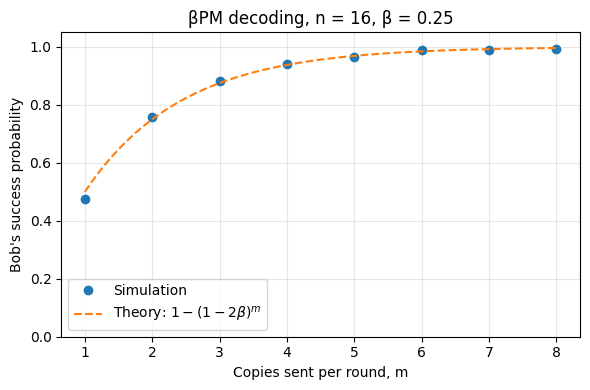

In [8]:
m_fine = np.linspace(1, 8, 100)
plt.figure(figsize=(6, 4))
plt.plot(m_values, success_rate, "o", label="Simulation")
plt.plot(m_fine, 1 - (1 - 2 * beta) ** m_fine, "--", label=r"Theory: $1-(1-2\beta)^m$")
plt.xlabel("Copies sent per round, m")
plt.ylabel("Bob's success probability")
plt.title(rf"βPM decoding, n = {n}, β = {beta}")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig2_bob_success_vs_copies.png", dpi=200)
plt.show()

## 3. Eavesdropper without the matching

Under the QCT assumption, Eve cannot decrypt $(M, \omega)$ until long after her quantum memory has decohered. She must therefore measure her copies **before** learning $M$, and keep only classical outcomes.

We simulate one natural attack. For each of her $m$ copies, Eve measures in a fresh random perfect matching and records the (edge, parity) result. Once $(M, \omega)$ becomes known, she recovers $a$ if any of her edges coincides with one of Bob's $\beta n$ edges, and otherwise guesses at random. Since each recorded edge is a uniformly random pair out of $\binom{n}{2}$,

$$P_{\text{guess}}^{\text{Eve}} = \tfrac12 + \tfrac12\left[1 - \left(1 - \tfrac{2\beta}{n-1}\right)^m\right] \;\longrightarrow\; \tfrac12 \quad (n \to \infty).$$

Bob discards aborted rounds during sifting, and on the rounds he keeps he knows $a$ with certainty. Because Bob's and Eve's outcomes come from independent copies, Eve's guessing probability is the same on those kept rounds. This is one specific attack, not an optimal one; the security analysis in the paper bounds general attacks under the noisy-storage assumption.

In [9]:
def eve_guess(eve_records, M, omega, rng):
    bob_edges = {frozenset(e): t for t, e in enumerate(M)}
    for edge, parity in eve_records:
        t = bob_edges.get(frozenset(edge))
        if t is not None:
            return int(parity ^ omega[t])
    return int(rng.integers(0, 2))


def run_eve(n, beta, m, trials, seed):
    rng = np.random.default_rng(seed)
    instances = [bpm_instance(n, beta, rng) for _ in range(trials)]

    circuits, eve_matchings = [], []
    for (x, M, omega, a) in instances:
        for _ in range(m):
            EM = random_perfect_matching(n, rng)
            eve_matchings.append(EM)
            circuits.append(hm_circuit(x, EM))
    result = sim.run(transpile(circuits, sim), shots=1, memory=True,
                     seed_simulator=seed).result()

    correct = 0
    for k, (x, M, omega, a) in enumerate(instances):
        records = []
        for c in range(k * m, (k + 1) * m):
            t, parity = decode(result.get_memory(c)[0])
            records.append((eve_matchings[c][t], parity))
        correct += int(eve_guess(records, M, omega, rng) == a)
    return correct / trials

In [10]:
beta, trials = 0.25, 500
n_values = [4, 8, 16, 32]
m_list = [1, 4]

eve_rates = {m: [run_eve(n, beta, m, trials, seed=10 * n + m) for n in n_values] for m in m_list}

for m in m_list:
    for n, p in zip(n_values, eve_rates[m]):
        theory = 0.5 + 0.5 * (1 - (1 - 2 * beta / (n - 1)) ** m)
        print(f"m = {m}  n = {n:2d}   Eve P_guess = {p:.3f}   theory = {theory:.3f}")

m = 1  n =  4   Eve P_guess = 0.528   theory = 0.583
m = 1  n =  8   Eve P_guess = 0.560   theory = 0.536
m = 1  n = 16   Eve P_guess = 0.518   theory = 0.517
m = 1  n = 32   Eve P_guess = 0.508   theory = 0.508
m = 4  n =  4   Eve P_guess = 0.730   theory = 0.759
m = 4  n =  8   Eve P_guess = 0.618   theory = 0.628
m = 4  n = 16   Eve P_guess = 0.542   theory = 0.563
m = 4  n = 32   Eve P_guess = 0.490   theory = 0.531


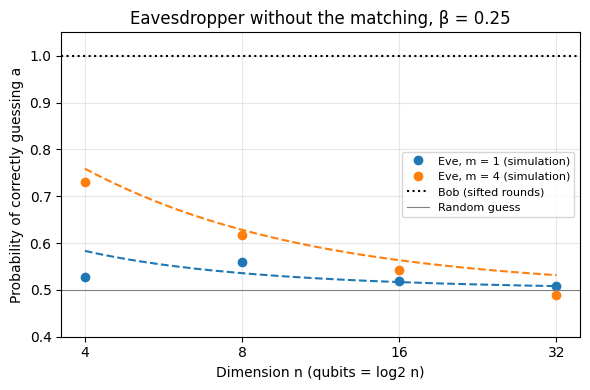

In [11]:
n_fine = np.linspace(4, 32, 200)
colors = {1: "tab:blue", 4: "tab:orange"}

plt.figure(figsize=(6, 4))
for m in m_list:
    c = colors[m]
    plt.plot(n_values, eve_rates[m], "o", color=c, label=f"Eve, m = {m} (simulation)")
    plt.plot(n_fine, 0.5 + 0.5 * (1 - (1 - 2 * beta / (n_fine - 1)) ** m), "--", color=c)
plt.axhline(1.0, color="black", linestyle=":", label="Bob (sifted rounds)")
plt.axhline(0.5, color="gray", linewidth=0.8, label="Random guess")
plt.xscale("log", base=2)
plt.xticks(n_values, [str(v) for v in n_values])
plt.xlabel("Dimension n (qubits = log2 n)")
plt.ylabel("Probability of correctly guessing a")
plt.title(rf"Eavesdropper without the matching, β = {beta}")
plt.ylim(0.4, 1.05)
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig3_eve_vs_bob.png", dpi=200)
plt.show()

## 4. Discussion

- The matching measurement returns the correct parity on every shot, with edges observed uniformly, matching the analytic prediction.
- With multiple copies, Bob's success probability follows $1-(1-2\beta)^m$ and is independent of $n$. Sending copies is what lets the protocol tolerate loss, which BB84 cannot do safely.
- On sifted rounds Bob recovers $a$ with certainty, while an eavesdropper who must measure before learning the matching gains little: her guessing probability approaches 1/2 as $n$ grows. Her advantage does increase with $m$, which is why the paper limits the number of copies (security holds for up to roughly $\sqrt{n}/\log n$ copies).

**Limitations.** The simulation is noiseless, Eve's strategy is a single heuristic attack rather than the optimal one, and the classical encryption layer is not yet included. Notebook 03 adds the encryption step and channel noise to complete the key exchange.